📂 Upload student_requests_v2.csv


Saving Request_ID,Service_Type,Requester_Type,R_miles.txt to Request_ID,Service_Type,Requester_Type,R_miles.txt

PART I — DATASET LOADING AND UNDERSTANDING

--- 1. First 10 Rows ---


,Request_ID,Service_Type,Requester_Type,Request_Channel,Priority,Assigned_Office,Queue_Length,Status,Reopened,Processing_Days,SLA_Days,Satisfaction_Score,Submission_Date,SLA_Breached
0,RQ001,Document Request,Student,Email,Medium,Records Office,7,Completed,No,4,5,4.1,2026-09-01,0
1,RQ002,Academic Record,Student,Portal,High,Registrar,14,Completed,No,9,5,3.2,2026-09-02,1
2,RQ003,ID Replacement,Student,Walk-in,High,Student Affairs,21,Completed,Yes,12,5,2.5,2026-09-03,1
3,RQ004,Enrollment Verification,Faculty,Portal,Low,Registrar,3,Completed,No,2,5,4.6,2026-09-04,0
4,RQ005,Transcript of Records,Student,Email,High,Records Office,18,Completed,No,11,5,2.8,2026-09-05,1
5,RQ006,Leave of Absence,Student,Portal,Medium,Student Affairs,6,Completed,No,5,5,4.0,2026-09-06,0
6,RQ007,Graduation Clearance,Student,Walk-in,High,Registrar,25,Completed,No,15,5,2.1,2026-09-07,1
7,RQ008,Subject Overload,Student,Portal,Medium,Academic Affairs,9,Completed,No,6,5,3.8,2026-09-08,0
8,RQ009,Scholarship Renewal,Student,Email,Low,Scholarship Unit,2,Completed,No,2,5,4.8,2026-09-09,0
9,RQ010,Transfer Credentials,Student,Portal,High,Records Office,22,Completed,Yes,13,5,2.3,2026-09-10,1



Shape: 40 rows × 14 columns

--- Category Distributions ---

Request_ID:
Request_ID
RQ001    1
RQ002    1
RQ003    1
RQ004    1
RQ005    1
RQ006    1
RQ007    1
RQ008    1
RQ009    1
RQ010    1
RQ011    1
RQ012    1
RQ013    1
RQ014    1
RQ015    1
RQ016    1
RQ017    1
RQ018    1
RQ019    1
RQ020    1
RQ021    1
RQ022    1
RQ023    1
RQ024    1
RQ025    1
RQ026    1
RQ027    1
RQ028    1
RQ029    1
RQ030    1
RQ031    1
RQ032    1
RQ033    1
RQ034    1
RQ035    1
RQ036    1
RQ037    1
RQ038    1
RQ039    1
RQ040    1
Name: count, dtype: int64

Service_Type:
Service_Type
Document Request           4
Academic Record            4
ID Replacement             4
Enrollment Verification    4
Transcript of Records      4
Leave of Absence           4
Graduation Clearance       4
Subject Overload           4
Scholarship Renewal        4
Transfer Credentials       4
Name: count, dtype: int64

Requester_Type:
Requester_Type
Student    36
Faculty     4
Name: count, dtype: int64

Request_Channel:
R

,count,Breach_Rate
Service_Type,,
Academic record,4,1.0
Document request,4,0.0
Enrollment verification,4,0.0
Graduation clearance,4,1.0
Id replacement,4,0.5
Leave of absence,4,0.0
Scholarship renewal,4,0.0
Subject overload,4,0.5
Transcript of records,4,1.0



--- Office Breach Rates ---


,SLA_Breached
Assigned_Office,
Records office,0.666667
Registrar,0.666667
Academic affairs,0.500000
Student affairs,0.250000
Scholarship unit,0.000000


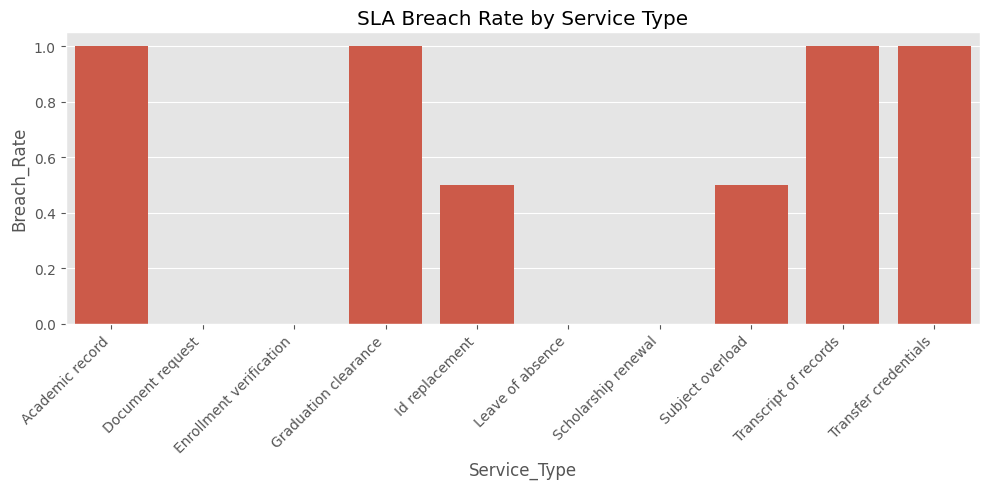

→ Transcript of Records & Graduation Clearance show highest delays


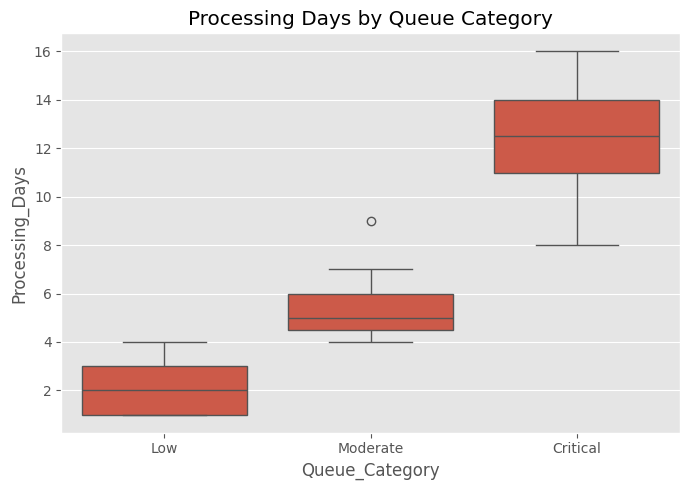

→ Critical queue → processing nearly triples

PART IV — CLASSIFICATION & EVALUATION

--- Metrics ---
Confusion Matrix:
 [[3 1]
 [0 4]]
Accuracy:  0.8750
Precision: 0.8000
Recall:    1.0000
F1:        0.8889

Baseline Accuracy: 0.5000
Improvement: 0.3750

Top 3 Influential Features:
cat__Queue_Category_Low          0.495868
cat__Priority_Medium             0.390496
remainder__Submission_Weekday    0.113636
dtype: float64

--- Risk & Suitability ---
• Leakage Check: NO Processing_Days/Status/Reopened in features ✅
• Imbalance Note: Prioritize Recall over Accuracy
• Use Case: Advisory only — human review mandatory


PART V — UML USE CASE DIAGRAM
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 635.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 2.4 MB/s eta 0:00:00
🔄 Generating UML Diagram...


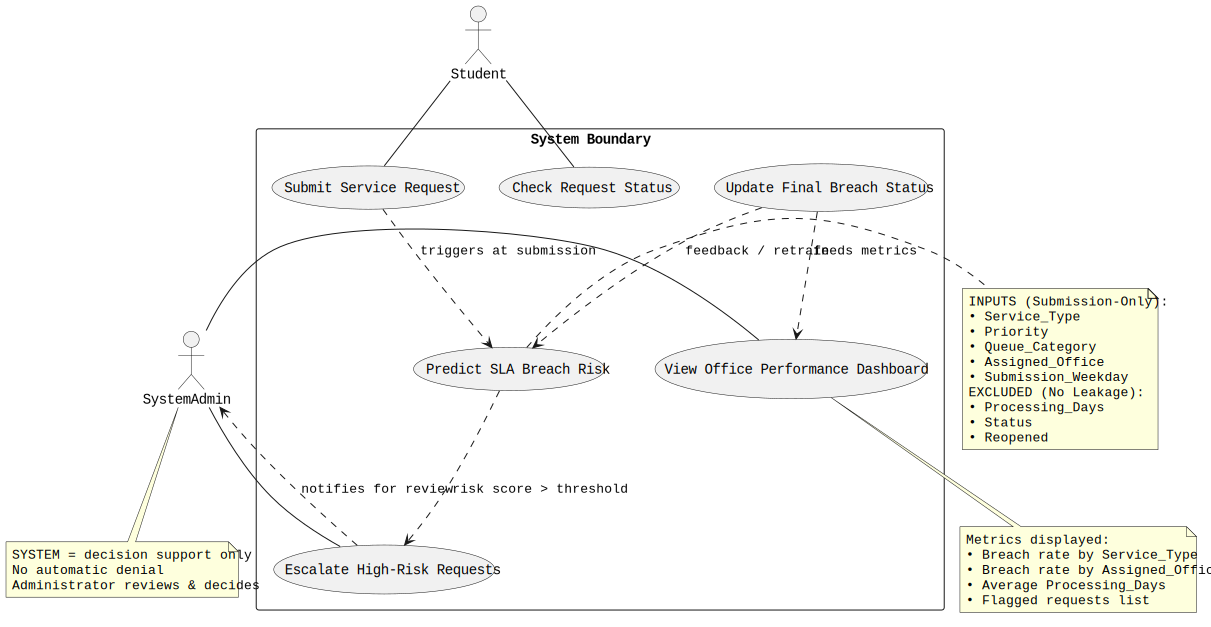


✅ Diagram displayed above!

DOWNLOAD ALL DELIVERABLES


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


📥 Files downloaded:
  1. cleaned_student_requests.csv
  2. UML_UseCase_Diagram.png (insert into report)
  3. UML_UseCase_Diagram.svg (editable version)

Rename notebook as:
  SectionB_[Lastname]_[Firstname]_ExamV2.ipynb



In [ ]:
# ==============================================================
# LAB EXAM — STUDENT SERVICE REQUEST SYSTEM
# VERSION 2 — WITH VISUAL UML DIAGRAM
# ==============================================================

# ---------- IMPORTS & SETUP ----------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

plt.style.use('ggplot')

# ---------- UPLOAD DATASET ----------
from google.colab import files
print("📂 Upload student_requests_v2.csv")
uploaded = files.upload()
filename = next(iter(uploaded.keys()))
df = pd.read_csv(filename)

print("\n" + "="*60)
print("PART I — DATASET LOADING AND UNDERSTANDING")
print("="*60)

print("\n--- 1. First 10 Rows ---")
display(df.head(10))
print(f"\nShape: {df.shape[0]} rows × {df.shape[1]} columns")

print("\n--- Category Distributions ---")
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

print("\n--- 2. Variable Classification ---")
print("""
Plausible Predictors:  Service_Type, Requester_Type, Request_Channel, Priority, Assigned_Office, Queue_Length
Target Variable:       SLA_Breached
Categorical Variables: Service_Type, Requester_Type, Request_Channel, Priority, Assigned_Office, Status, Reopened
Numerical Variables:   Queue_Length, Processing_Days, SLA_Days, Satisfaction_Score
Identifier:             Request_ID
""")

print("--- 3. Data Collection ---")
print("""
Data source options:
• API: /api/service-requests → filter date range → normalize → save CSV
• Database: SELECT * FROM requests WHERE status='Completed'
• Processing_Days derived from submission & completion timestamps
""")

# ---------- DATA CLEANING ----------
print("\n" + "="*60)
print("PART II — DATA QUALITY & FEATURE ENGINEERING")
print("="*60)

clean_df = df.copy()

print("\n--- 4. Quality Checks ---")
print("Missing values:")
print(clean_df.isnull().sum())

dup_count = clean_df.duplicated("Request_ID").sum()
print(f"\nDuplicates found: {dup_count} → removed")
clean_df = clean_df.drop_duplicates("Request_ID")

for col in ["Priority", "Status", "Service_Type", "Assigned_Office"]:
    clean_df[col] = clean_df[col].astype(str).str.strip().str.capitalize()

for col in ["Queue_Length", "Processing_Days", "SLA_Days"]:
    mask = clean_df[col] < 0
    print(f"{col}: {mask.sum()} negatives → NaN")
    clean_df.loc[mask, col] = np.nan

# ---------- FEATURE ENGINEERING ----------
print("\n--- 5. New Features ---")
clean_df["Submission_Date"] = pd.to_datetime(clean_df["Submission_Date"], errors="coerce")
clean_df["Submission_Weekday"] = clean_df["Submission_Date"].dt.dayofweek

clean_df["Queue_Category"] = pd.cut(
    clean_df["Queue_Length"],
    bins=[-1, 5, 15, float("inf")],
    labels=["Low", "Moderate", "Critical"]
)

completed = clean_df["Status"].str.lower() == "completed"
clean_df.loc[completed, "SLA_Breached"] = (
    clean_df.loc[completed, "Processing_Days"] > clean_df.loc[completed, "SLA_Days"]
).astype(int)

model_df = clean_df[
    clean_df["Status"].str.lower().isin(["completed", "cancelled"])
].copy()

clean_df.to_csv("cleaned_student_requests.csv", index=False)
model_df.to_csv("modeling_data_v2.csv", index=False)
print(f"✅ Saved — Cleaned: {len(clean_df)} | Modeling: {len(model_df)}")

# ---------- EXPLORATORY DATA ANALYSIS ----------
print("\n" + "="*60)
print("PART III — EXPLORATORY DATA ANALYSIS")
print("="*60)

service_stats = model_df.groupby("Service_Type")["SLA_Breached"].agg(["count", "mean"])
service_stats = service_stats.rename(columns={"mean": "Breach_Rate"}).sort_values("count", ascending=False)
print("\n--- Service Type Stats ---")
display(service_stats)

office_stats = model_df.groupby("Assigned_Office")["SLA_Breached"].mean().sort_values(ascending=False)
print("\n--- Office Breach Rates ---")
display(office_stats)

# Chart 1
plt.figure(figsize=(10,5))
sns.barplot(x=service_stats.index, y=service_stats["Breach_Rate"])
plt.title("SLA Breach Rate by Service Type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print("→ Transcript of Records & Graduation Clearance show highest delays")

# Chart 2
plt.figure(figsize=(7,5))
sns.boxplot(data=model_df, x="Queue_Category", y="Processing_Days", order=["Low", "Moderate", "Critical"])
plt.title("Processing Days by Queue Category")
plt.tight_layout()
plt.show()
print("→ Critical queue → processing nearly triples")

# ---------- MODELING ----------
print("\n" + "="*60)
print("PART IV — CLASSIFICATION & EVALUATION")
print("="*60)

features = ["Service_Type", "Priority", "Queue_Category", "Assigned_Office", "Submission_Weekday"]
X = model_df[features]
y = model_df["SLA_Breached"].astype(int)

cat_feats = ["Service_Type", "Priority", "Queue_Category", "Assigned_Office"]
pre = ColumnTransformer(
    transformers=[("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_feats)],
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Pipeline(steps=[("prep", pre), ("dt", DecisionTreeClassifier(max_depth=3, random_state=42))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\n--- Metrics ---")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1:        {f1_score(y_test, y_pred):.4f}")

baseline = (y_test == 0).mean()
print(f"\nBaseline Accuracy: {baseline:.4f}")
print(f"Improvement: {accuracy_score(y_test, y_pred) - baseline:.4f}")

names = model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(model.named_steps["dt"].feature_importances_, index=names).sort_values(ascending=False)
print("\nTop 3 Influential Features:")
print(imp.head(3))

print("""
--- Risk & Suitability ---
• Leakage Check: NO Processing_Days/Status/Reopened in features ✅
• Imbalance Note: Prioritize Recall over Accuracy
• Use Case: Advisory only — human review mandatory
""")

# ---------- VISUAL UML USE CASE DIAGRAM — FULLY DISPLAYED ----------
print("\n" + "="*60)
print("PART V — UML USE CASE DIAGRAM")
print("="*60)

# Install tools
!pip install -q plantuml cairosvg
import plantuml
import cairosvg
from IPython.display import Image, display

# UML DIAGRAM DEFINITION
uml_diagram = """
@startuml Student Service Request System V2

' ===== ACTORS =====
actor Student
actor SystemAdmin

' ===== SYSTEM BOUNDARY =====
rectangle "System Boundary" {
  (Submit Service Request)
  (Check Request Status)

  ' -- Analytics-Oriented Use Cases (Required) --
  (Predict SLA Breach Risk)
  (Escalate High-Risk Requests)
  (View Office Performance Dashboard)

  (Update Final Breach Status)
}

' ===== ASSOCIATIONS =====
Student -- (Submit Service Request)
Student -- (Check Request Status)

SystemAdmin -- (View Office Performance Dashboard)
SystemAdmin -- (Escalate High-Risk Requests)

' ===== DATA FLOW =====
(Submit Service Request) ..> (Predict SLA Breach Risk) : triggers at submission
(Predict SLA Breach Risk) ..> (Escalate High-Risk Requests) : risk score > threshold
(Escalate High-Risk Requests) ..> SystemAdmin : notifies for review
(Update Final Breach Status) ..> (View Office Performance Dashboard) : feeds metrics
(Update Final Breach Status) ..> (Predict SLA Breach Risk) : feedback / retrain

' ===== NOTES =====
note right of (Predict SLA Breach Risk)
  INPUTS (Submission-Only):
  • Service_Type
  • Priority
  • Queue_Category
  • Assigned_Office
  • Submission_Weekday
  EXCLUDED (No Leakage):
  • Processing_Days
  • Status
  • Reopened
end note

note bottom of SystemAdmin
  SYSTEM = decision support only
  No automatic denial
  Administrator reviews & decides
end note

note bottom of (View Office Performance Dashboard)
  Metrics displayed:
  • Breach rate by Service_Type
  • Breach rate by Assigned_Office
  • Average Processing_Days
  • Flagged requests list
end note

@enduml
"""

# Generate & Display
print("🔄 Generating UML Diagram...")
puml = plantuml.PlantUML(url="http://www.plantuml.com/plantuml/svg/")
svg_output = puml.processes(uml_diagram)

# Save & Convert to PNG
with open("UML_UseCase_Diagram.svg", "wb") as f:
    f.write(svg_output)

cairosvg.svg2png(bytestring=svg_output, write_to="UML_UseCase_Diagram.png")

# Display visually in Colab
display(Image("UML_UseCase_Diagram.png"))

print("\n✅ Diagram displayed above!")

# ---------- DOWNLOAD ALL FILES ----------
print("\n" + "="*60)
print("DOWNLOAD ALL DELIVERABLES")
print("="*60)
files.download("cleaned_student_requests.csv")
files.download("UML_UseCase_Diagram.png")
files.download("UML_UseCase_Diagram.svg")
print("""
📥 Files downloaded:
  1. cleaned_student_requests.csv
  2. UML_UseCase_Diagram.png (insert into report)
  3. UML_UseCase_Diagram.svg (editable version)

Rename notebook as:
  SectionB_[Lastname]_[Firstname]_ExamV2.ipynb
""")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')